# Diplomado de Inteligencia Artificial
## Laboratorio: Redes Convolucionales
### AlexNet, ResNet y qué aprenden las CNNs
---

En la clase vimos qué es una **convolución**, cómo se arma una **red convolucional (CNN)**, qué **aprenden** sus capas y por qué la **conexión residual** de ResNet permitió redes mucho más profundas. En este laboratorio vamos a ver todo eso **funcionando de verdad**.

**¿Qué vamos a hacer?**

1. **Parte 1:** revisar la convolución de la clase en PyTorch y armar **AlexNet desde cero**.
2. **Parte 2:** entrenar una **ResNet-18** para reconocer 102 tipos de flores, **desde cero** y con **fine-tuning**, y comparar.
3. **Parte 3:** mirar por dentro **qué aprendió** la ResNet-18 en sus primeras capas.

**Antes de empezar:**

* Activen la GPU: menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU** (por ejemplo, T4).
* Ejecuten las celdas **en orden** con `Shift + Enter`.
* Con GPU, todo el laboratorio tarda alrededor de **25 minutos** de cómputo.
* No hay actividades evaluadas: la idea es ejecutar, mirar y jugar. Cambien números y vean qué pasa.

## 0. Preparación

Importamos las librerías y fijamos una **semilla** para que los resultados sean reproducibles.

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from IPython.display import clear_output

torch.manual_seed(0)
np.random.seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Vamos a usar:", device)
if device == "cpu":
    print("=" * 70)
    print("⚠️  ¡OJO! No hay GPU activa.")
    print("   Actívenla en: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU")
    print("   y vuelvan a ejecutar desde aquí. En CPU este lab puede tardar MÁS DE 2 HORAS")
    print("   (si no hay otra opción, usen EPOCAS = 3 en la Parte 2).")
    print("=" * 70)

INICIO_LAB = time.time()

Vamos a usar: cuda


In [ ]:
# @title Colores y funciones para graficar (pueden ignorar esta celda) { display-mode: "form" }
from matplotlib.colors import LinearSegmentedColormap

ROSA, MORADO, AZUL, GRIS = "#E62A85", "#454077", "#2B2B62", "#888888"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": AZUL,
    "axes.titlecolor": AZUL,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
cmap_rosa = LinearSegmentedColormap.from_list("rosa", ["white", ROSA])


def miles(n):
    # 1234567 -> "1.234.567"
    return f"{n:,}".replace(",", ".")


def mostrar_matriz(ax, matriz, titulo, cmap=cmap_rosa):
    # Dibuja una matriz pequeña con sus números adentro
    matriz = np.asarray(matriz)
    ax.imshow(matriz, cmap=cmap, vmin=min(0, matriz.min()), vmax=max(1, matriz.max()))
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            ax.text(j, i, f"{v:g}", ha="center", va="center", fontsize=12,
                    color="white" if v > matriz.max() / 2 and v > 0 else AZUL)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(titulo)

## Parte 1: La convolución y AlexNet desde cero

### 1.1 La convolución de la clase, en PyTorch

¿Se acuerdan del ejemplo de la clase? La entrada tenía una **"U"** al centro y el filtro también era una **"U"**. Por eso, en el centro del mapa de activación salía un **7**: ahí la entrada se parece al filtro.

En PyTorch, la convolución es `F.conv2d`. Recibe tensores con forma `(batch, canales, alto, ancho)`, así que agregamos dos dimensiones de tamaño 1.

Forma de la salida: (1, 1, 3, 3)
tensor([[1., 4., 1.],
        [2., 7., 2.],
        [1., 4., 1.]])


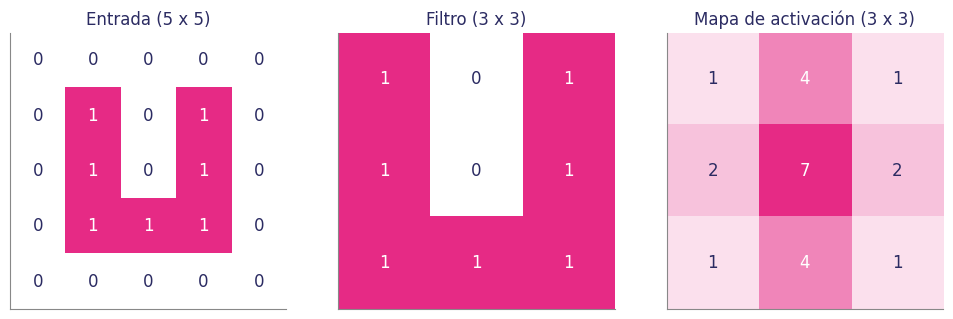

In [ ]:
entrada = torch.tensor([[0, 0, 0, 0, 0],
                  [0, 1, 0, 1, 0],
                  [0, 1, 0, 1, 0],
                  [0, 1, 1, 1, 0],
                  [0, 0, 0, 0, 0]], dtype=torch.float32)
filtro = torch.tensor([[1, 0, 1],
                  [1, 0, 1],
                  [1, 1, 1]], dtype=torch.float32)

mapa = F.conv2d(entrada[None, None], filtro[None, None])      # (1, 1, 5, 5) * (1, 1, 3, 3)
print("Forma de la salida:", tuple(mapa.shape))
print(mapa[0, 0])

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
mostrar_matriz(axes[0], entrada, "Entrada (5 x 5)")
mostrar_matriz(axes[1], filtro, "Filtro (3 x 3)")
mostrar_matriz(axes[2], mapa[0, 0], "Mapa de activación (3 x 3)")
plt.tight_layout()
plt.show()

¡Lo mismo de la diapositiva! El **7** del centro es donde el filtro "encontró" su patrón.

Probemos ahora el **stride** y el **padding**, igual que en la clase:

In [ ]:
con_stride = F.conv2d(entrada[None, None], filtro[None, None], stride=2)
con_padding = F.conv2d(entrada[None, None], filtro[None, None], padding=1)
print("stride = 2  -> forma", tuple(con_stride.shape[-2:]))
print(con_stride[0, 0])
print("\npadding = 1 -> forma", tuple(con_padding.shape[-2:]))
print(con_padding[0, 0])

stride = 2  -> forma (2, 2)
tensor([[1., 1.],
        [1., 1.]])

padding = 1 -> forma (5, 5)
tensor([[1., 1., 2., 1., 1.],
        [2., 1., 4., 1., 2.],
        [3., 2., 7., 2., 3.],
        [2., 1., 4., 1., 2.],
        [1., 1., 2., 1., 1.]])


Con `stride=2` el filtro salta posiciones y el mapa queda de $2\times2$. Con `padding=1` el filtro también se centra en los bordes y el mapa mantiene el tamaño de la entrada ($5\times5$).

> En una CNN de verdad, los números de `filtro` **no los elegimos nosotros**: son parámetros que la red aprende con *backpropagation*.

### 1.2 Armando AlexNet

Recordemos la estructura de AlexNet (diapositiva "AlexNet (2012)"): **5 capas convolucionales** y **3 capas lineales**.

| Capa | Filtros | Kernel | Stride | Padding | MaxPool ($3\times3$, stride 2) |
|---|---|---|---|---|---|
| conv1 | 96 | $11\times11$ | 4 | 2 | sí |
| conv2 | 256 | $5\times5$ | 1 | 2 | sí |
| conv3 | 384 | $3\times3$ | 1 | 1 | no |
| conv4 | 384 | $3\times3$ | 1 | 1 | no |
| conv5 | 256 | $3\times3$ | 1 | 1 | sí |
| fc6 | 4096 neuronas | | | | |
| fc7 | 4096 neuronas | | | | |
| fc8 | 1000 neuronas (una por clase de ImageNet) | | | | |

En PyTorch, una red se escribe como una **clase** que hereda de `nn.Module`, igual que el MLP del laboratorio anterior: en `__init__` creamos las piezas y en `forward` las conectamos.

In [ ]:
class AlexNet(nn.Module):                   # Esta clase representa nuestro modelo

    def __init__(self):   # Constructor: aquí armamos las piezas de nuestra red
        super().__init__()
        # Bloques convolucionales: convolución, max pooling y activación (ReLU)

        # Entrada = 3 x 224 x 224  Salida = 96 x 55 x 55 --> MaxPool = 96 x 27 x 27
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3,           # canales de entrada (RGB)
                      out_channels=96,         # cantidad de filtros
                      kernel_size=(11, 11),    # tamaño del filtro
                      stride=(4, 4),           # stride
                      padding=(2, 2)),         # padding
            nn.MaxPool2d(kernel_size=(3, 3), stride=(2, 2)),
            nn.ReLU()
        )
        # Entrada = 96 x 27 x 27  Salida = 256 x 27 x 27 --> MaxPool = 256 x 13 x 13
        self.conv2 = nn.Sequential(
            nn.Conv2d(96, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2)),
            nn.MaxPool2d(kernel_size=(3, 3), stride=(2, 2)),
            nn.ReLU()
        )
        # Entrada = 256 x 13 x 13  Salida = 384 x 13 x 13
        self.conv3 = nn.Sequential(
            nn.Conv2d(256, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.ReLU()
        )
        # Entrada = 384 x 13 x 13  Salida = 384 x 13 x 13
        self.conv4 = nn.Sequential(
            nn.Conv2d(384, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.ReLU()
        )
        # Entrada = 384 x 13 x 13  Salida = 256 x 13 x 13 --> MaxPool = 256 x 6 x 6
        self.conv5 = nn.Sequential(
            nn.Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.MaxPool2d(kernel_size=(3, 3), stride=(2, 2)),
            nn.ReLU()
        )
        # Aplanamos para pasar de los mapas de activación a las capas lineales
        self.flat = nn.Flatten()
        # Bloques lineales (como el MLP)
        # Entrada = 256 x 6 x 6 = 9216  Salida = 4096
        self.fc6 = nn.Sequential(nn.Linear(9216, 4096), nn.ReLU())
        # Entrada = 4096  Salida = 4096
        self.fc7 = nn.Sequential(nn.Linear(4096, 4096), nn.ReLU())
        # Entrada = 4096  Salida = 1000 (una por clase)
        self.fc8 = nn.Linear(4096, 1000)

    def forward(self, x):        # Aquí conectamos las piezas, una detrás de la otra
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)
        x = self.flat(x)
        x = self.fc6(x)
        x = self.fc7(x)
        x = self.fc8(x)
        return x

### 1.3 ¿De qué tamaño queda cada mapa de activación?

Al pasar a las capas lineales necesitamos saber **cuántas neuronas** salen de la última capa convolucional. Para eso usamos la fórmula de la clase:

$$H_{\text{salida}} = \left\lfloor\frac{H - K + 2P}{S}\right\rfloor + 1$$

donde $H$ es el alto (o ancho) de la entrada, $K$ el kernel size, $P$ el padding y $S$ el stride. Por ejemplo, para la primera capa de AlexNet:

$$\left\lfloor \frac{224 - 11 + 2\cdot2}{4}\right\rfloor + 1 = 55$$

Usen la calculadora: cambien los valores y vean cómo cambia la salida.

In [ ]:
# @title Calculadora de dimensión de salida { run: "auto" }
from math import floor

H = 224  # @param {type:"integer"}
K = 11  # @param {type:"integer"}
S = 4  # @param {type:"integer"}
P = 2  # @param {type:"integer"}

salida = floor((H - K + 2 * P) / S) + 1
print(f"La salida es de {salida} x {salida}.")

La salida es de 55 x 55.


La cantidad de **neuronas** a la salida de una capa convolucional es $C_{\text{salida}} \cdot H \cdot W$. Por ejemplo, al final de `conv5` tenemos $256 \cdot 6 \cdot 6 = 9216$: ¡justo la entrada de `fc6`!

In [ ]:
# @title Calculadora de neuronas { run: "auto" }
C_salida = 256  # @param {type:"integer"}
H = 6  # @param {type:"integer"}
W = 6  # @param {type:"integer"}

print(f"La cantidad de neuronas es {miles(C_salida * H * W)}.")

La cantidad de neuronas es 9.216.


### 1.4 ¿Cuántos parámetros tiene?

De la clase: una capa convolucional tiene $C_{\text{entrada}} \cdot K \cdot K \cdot C_{\text{salida}} + C_{\text{salida}}$ parámetros (los pesos de los filtros más un sesgo por filtro).

In [ ]:
# @title Calculadora de parámetros de una capa convolucional { run: "auto" }
C_entrada = 3  # @param {type:"integer"}
C_salida = 96  # @param {type:"integer"}
K = 11  # @param {type:"integer"}
usar_sesgo = True  # @param {type:"boolean"}

params = C_entrada * C_salida * K * K + (C_salida if usar_sesgo else 0)
print(f"La cantidad de parámetros es {miles(params)}.")

La cantidad de parámetros es 34.944.


Ahora contemos los parámetros de toda la red con PyTorch, capa por capa:

In [ ]:
def contar_parametros(modelo):
    total = 0
    for nombre, modulo in modelo.named_children():
        n = sum(p.numel() for p in modulo.parameters())
        if n:
            print(f"{nombre:6s} {miles(n):>12s} parámetros")
        total += n
    print(f"{'Total':6s} {miles(total):>12s} parámetros")
    return total


alex = AlexNet()
total = contar_parametros(alex)

convolucionales = sum(p.numel() for nombre, m in alex.named_children() if nombre.startswith("conv")
                      for p in m.parameters())
print(f"\nLas capas convolucionales son solo el {convolucionales / total:.0%} de los parámetros.")
print(f"El MLP de MNIST del laboratorio anterior tenía {miles(109386)} parámetros.")

conv1        34.944 parámetros
conv2       614.656 parámetros
conv3       885.120 parámetros
conv4     1.327.488 parámetros
conv5       884.992 parámetros
fc6      37.752.832 parámetros
fc7      16.781.312 parámetros
fc8       4.097.000 parámetros
Total    62.378.344 parámetros

Las capas convolucionales son solo el 6% de los parámetros.
El MLP de MNIST del laboratorio anterior tenía 109.386 parámetros.


Fíjense: casi todos los parámetros están en las **capas lineales**, ¡no en las convolucionales! Es lo que vimos en la diapositiva "Las capas lineales son caras": un filtro pequeño se reutiliza en toda la imagen, mientras que una capa lineal necesita un peso por cada par entrada–salida.

### 1.5 Probando la red

Para verificar que las dimensiones calzan, pasamos un minibatch de 10 imágenes **aleatorias**. Si alguna capa no entrega la forma que espera la siguiente, PyTorch lanza un error.

In [ ]:
datos_random = torch.randn((10, 3, 224, 224))
resultado = alex(datos_random)
print("Entrada:", tuple(datos_random.shape), "-> 10 imágenes RGB de 224 x 224")
print("Salida: ", tuple(resultado.shape), "      -> 10 ejemplos, 1000 números cada uno")

Entrada: (10, 3, 224, 224) -> 10 imágenes RGB de 224 x 224
Salida:  (10, 1000)       -> 10 ejemplos, 1000 números cada uno


### 1.6 AlexNet de verdad

Nuestra AlexNet tiene pesos **aleatorios**: no sabe nada. Entrenarla en ImageNet (1,2 millones de imágenes) toma días, así que usemos la versión **ya entrenada** que trae `torchvision` y probémosla con fotos que no están en ImageNet.

> La versión de `torchvision` es una variante de la nuestra: usa menos filtros en varias capas (por ejemplo, 64 en `conv1` en vez de 96) y agrega *dropout*, pero la idea es la misma.

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 164MB/s]


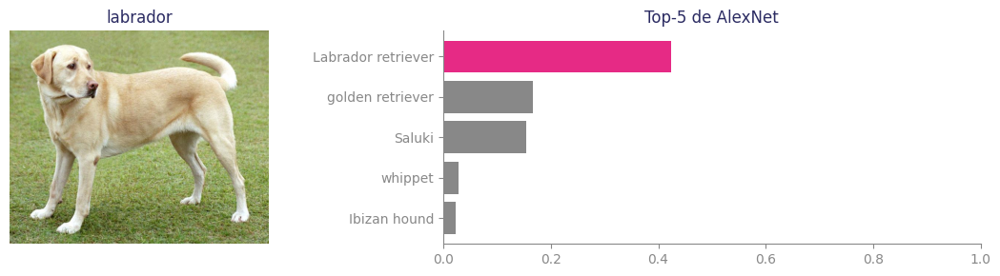

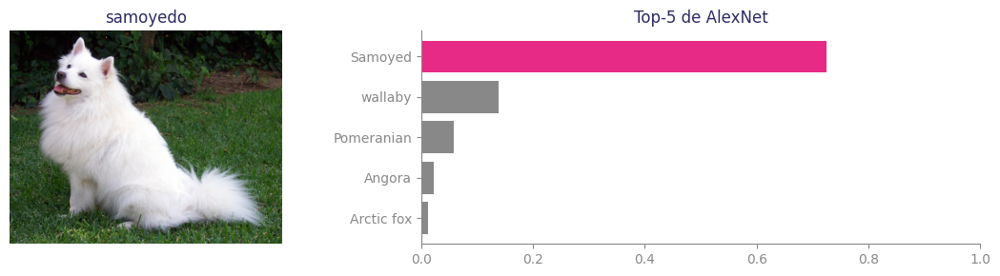

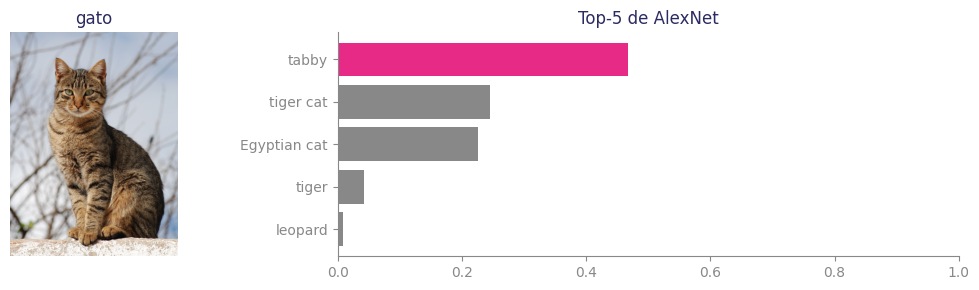

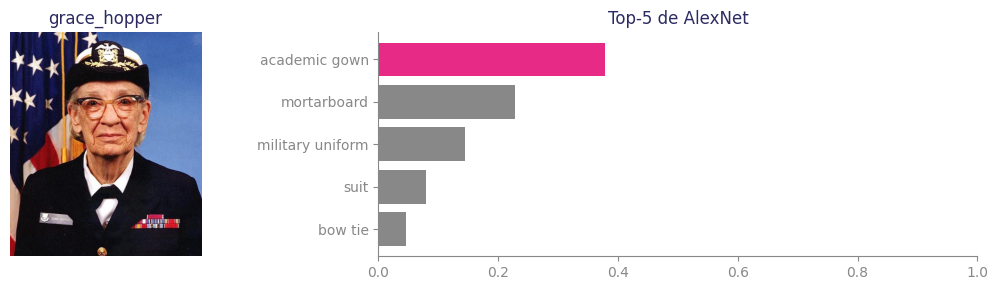

In [ ]:
import io
import requests
from PIL import Image
from torchvision.models import alexnet, AlexNet_Weights

pesos_alex = AlexNet_Weights.IMAGENET1K_V1
alex_entrenada = alexnet(weights=pesos_alex).eval()       # eval(): modo "uso"
preprocesar = pesos_alex.transforms()                     # resize 256 -> recorte 224 -> normaliza
categorias = pesos_alex.meta["categories"]                # los 1000 nombres de ImageNet

URLS = {
    "labrador": "https://upload.wikimedia.org/wikipedia/commons/2/26/YellowLabradorLooking_new.jpg",
    "samoyedo": "https://github.com/pytorch/hub/raw/master/images/dog.jpg",
    "gato": "https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2010-1a.jpg",
    "grace_hopper": "https://storage.googleapis.com/download.tensorflow.org/example_images/grace_hopper.jpg",
}
HEADERS = {"User-Agent": "Mozilla/5.0 (Colab CENIA lab)"}  # Wikimedia exige User-Agent


def descargar(url):
    r = requests.get(url, headers=HEADERS, timeout=20)
    r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")


@torch.no_grad()
def predecir(img, nombre):
    x = preprocesar(img).unsqueeze(0)                     # (1, 3, 224, 224)
    probs = alex_entrenada(x)[0].softmax(dim=0)           # 1000 probabilidades
    top_p, top_i = probs.topk(5)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [1, 1.6]})
    ax[0].imshow(img); ax[0].axis("off"); ax[0].set_title(nombre)
    colores = [ROSA] + [GRIS] * 4
    ax[1].barh(range(5)[::-1], top_p.numpy(), color=colores)
    ax[1].set_yticks(range(5)[::-1])
    ax[1].set_yticklabels([categorias[i] for i in top_i])
    ax[1].set_xlim(0, 1)
    ax[1].set_title("Top-5 de AlexNet")
    plt.tight_layout()
    plt.show()


for nombre, url in URLS.items():
    try:
        predecir(descargar(url), nombre)
    except Exception as e:
        print(f"[{nombre}] no se pudo descargar: {e}")

¡Bastante bien para una red de 2012! En la Parte 2 vamos a usar una red más moderna, **ResNet-18**, y vamos a ver qué tanto ayuda partir de una red ya entrenada.

## Parte 2: ResNet-18 en Flowers102, desde cero vs. fine-tuning

En la clase vimos que una red entrenada en ImageNet **ya sabe ver**: bordes, texturas, partes. La idea del **transfer learning** es reutilizar ese conocimiento: cambiamos la última capa por una con nuestras clases y seguimos entrenando con nuestros datos (**fine-tuning**).

Vamos a ponerlo a prueba con un problema difícil:

* **Flowers102**: fotos de **102 tipos de flores**, con apenas **10 fotos de entrenamiento por clase** (1.020 en total).
* Vamos a entrenar **dos** ResNet-18 con **los mismos datos** y **las mismas épocas**:
    * **(A) Desde cero**: pesos aleatorios. Tiene que aprender a ver con muy pocos ejemplos.
    * **(B) Fine-tuning**: parte de los pesos aprendidos en ImageNet.

¿Cuál creen que gana, y por cuánto? Anoten su apuesta antes de seguir.

### 2.1 Los datos

`torchvision` descarga Flowers102 directamente (unos 330 MB). Si ya está descargado, no lo vuelve a bajar.

Antes de entrar a la red, cada imagen se **transforma**:

* **Entrenamiento**: un recorte aleatorio de $224\times224$ y, a veces, un espejo horizontal. Así la red ve versiones un poco distintas de la misma foto en cada época (*data augmentation*).
* **Validación y test**: siempre el mismo recorte central de $224\times224$.
* En ambos casos se **normaliza** con la media y desviación de ImageNet, que es lo que espera la ResNet preentrenada.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

transf_entrenamiento = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.3, 1.0)),   # recorte de al menos 30% de la foto
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
transf_evaluacion = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

try:
    train_ds = datasets.Flowers102(root="datos", split="train", transform=transf_entrenamiento, download=True)
    val_ds = datasets.Flowers102(root="datos", split="val", transform=transf_evaluacion, download=True)
    test_ds = datasets.Flowers102(root="datos", split="test", transform=transf_evaluacion, download=True)
except Exception as e:
    raise RuntimeError(
        "No se pudo descargar Flowers102 (el servidor de Oxford a veces está lento). "
        "Esperen un momento y vuelvan a ejecutar esta celda.") from e

TAMANO_BATCH = 32
train_loader = DataLoader(train_ds, batch_size=TAMANO_BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=128, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=128, num_workers=2, pin_memory=True)

print(f"Entrenamiento: {len(train_ds)} imágenes | Validación: {len(val_ds)} | Test: {len(test_ds)}")

100%|██████████| 345M/345M [00:30<00:00, 11.1MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.95MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 26.4MB/s]

Entrenamiento: 1020 imágenes | Validación: 1020 | Test: 6149


In [ ]:
# @title Nombres de las 102 flores (pueden ignorar esta celda) { display-mode: "form" }
nombres_clases = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea",
    "english marigold", "tiger lily", "moon orchid", "bird of paradise", "monkshood",
    "globe thistle", "snapdragon", "colt's foot", "king protea", "spear thistle",
    "yellow iris", "globe-flower", "purple coneflower", "peruvian lily", "balloon flower",
    "giant white arum lily", "fire lily", "pincushion flower", "fritillary", "red ginger",
    "grape hyacinth", "corn poppy", "prince of wales feathers", "stemless gentian",
    "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower",
    "great masterwort", "siam tulip", "lenten rose", "barbeton daisy", "daffodil",
    "sword lily", "poinsettia", "bolero deep blue", "wallflower", "marigold", "buttercup",
    "oxeye daisy", "common dandelion", "petunia", "wild pansy", "primula", "sunflower",
    "pelargonium", "bishop of llandaff", "gaura", "geranium", "orange dahlia",
    "pink-yellow dahlia", "cautleya spicata", "japanese anemone", "black-eyed susan",
    "silverbush", "californian poppy", "osteospermum", "spring crocus", "bearded iris",
    "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose", "thorn apple",
    "morning glory", "passion flower", "lotus", "toad lily", "anthurium", "frangipani",
    "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia",
    "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "ball moss",
    "foxglove", "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia",
    "blanket flower", "trumpet creeper", "blackberry lily",
]
assert len(nombres_clases) == 102


def desnormalizar(x):
    # Deshace la normalización para poder mostrar la imagen: (3, H, W) -> (H, W, 3)
    media = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x.cpu() * std + media).clamp(0, 1).permute(1, 2, 0).numpy()


def mostrar_flores(imagenes, titulos, colores=None, columnas=8):
    filas = int(np.ceil(len(imagenes) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(columnas * 1.9, filas * 2.2))
    for i, ax in enumerate(np.array(axes).reshape(-1)):
        ax.axis("off")
        if i < len(imagenes):
            ax.imshow(desnormalizar(imagenes[i]))
            ax.set_title(titulos[i], fontsize=8,
                         color=colores[i] if colores is not None else AZUL)
    plt.tight_layout()
    plt.show()

Miremos algunas fotos de entrenamiento (ya transformadas: recortadas y a veces en espejo):

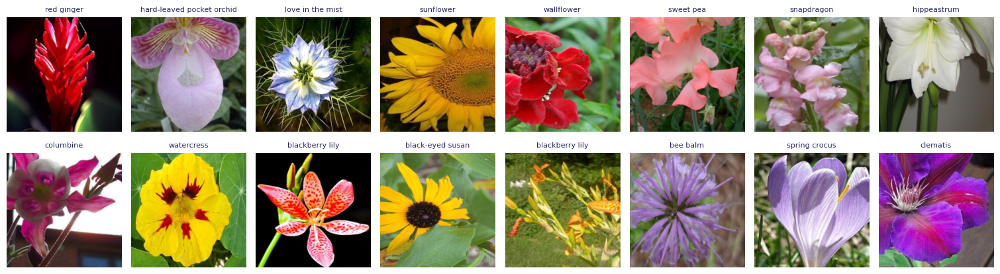

In [ ]:
imagenes, etiquetas = next(iter(DataLoader(train_ds, batch_size=16, shuffle=True)))
mostrar_flores(imagenes, [nombres_clases[e] for e in etiquetas])

### 2.2 El modelo: ResNet-18 con una capa final nueva

Es la ResNet-18 de la diapositiva: `conv1`, cuatro etapas `layer1` a `layer4` de bloques residuales, y al final una capa lineal `fc`. La ResNet de `torchvision` termina en `fc` con 1000 salidas (las clases de ImageNet). La **reemplazamos** por una capa nueva con **102 salidas**, una por flor:

* Entrada de `fc`: **512** (los canales de `layer4`, después del *average pooling*).
* Salida: **102**.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights


def crear_resnet18(preentrenada):
    pesos = ResNet18_Weights.IMAGENET1K_V1 if preentrenada else None
    modelo = resnet18(weights=pesos)
    modelo.fc = nn.Linear(512, 102)          # capa final nueva: 102 flores
    return modelo.to(device)


modelo_prueba = crear_resnet18(preentrenada=False)
print("Capa final:", modelo_prueba.fc)
print("Parámetros:", miles(sum(p.numel() for p in modelo_prueba.parameters())))
print("Salida para un batch de 2 imágenes:",
      tuple(modelo_prueba(torch.randn(2, 3, 224, 224).to(device)).shape))
del modelo_prueba

Capa final: Linear(in_features=512, out_features=102, bias=True)
Parámetros: 11.228.838
Salida para un batch de 2 imágenes: (2, 102)


### 2.3 El ciclo de entrenamiento

Es el **mismo ciclo** del laboratorio anterior: tomar un minibatch, forward pass, pérdida, backpropagation y actualizar. El único cambio es el optimizador: usamos SGD con *momentum*, una variante que suele entrenar más rápido.

In [ ]:
# @title Gráfico del progreso del entrenamiento (pueden ignorar esta celda) { display-mode: "form" }
torch.manual_seed(1)
_idx_muestra = torch.randperm(len(val_ds))[:8]
muestra_x = torch.stack([val_ds[i][0] for i in _idx_muestra])
muestra_y = torch.tensor([val_ds[i][1] for i in _idx_muestra])


def graficar_progreso(hist, model, titulo=""):
    model.eval()
    with torch.no_grad():
        preds = model(muestra_x.to(device)).argmax(dim=1).cpu()

    fig = plt.figure(figsize=(15, 6))
    grid = fig.add_gridspec(2, 8, height_ratios=[1.5, 1])
    epocas = range(1, len(hist["perdida"]) + 1)

    ax = fig.add_subplot(grid[0, :4])
    ax.plot(epocas, hist["perdida"], "o-", color=ROSA, label="entrenamiento")
    ax.plot(epocas, hist["val_perdida"], "o-", color=MORADO, label="validación")
    ax.set_xlabel("época")
    ax.set_title("Pérdida (mientras más chica, mejor)")
    ax.legend()

    ax = fig.add_subplot(grid[0, 4:])
    ax.plot(epocas, hist["val_precision"], "o-", color=MORADO)
    ax.set_ylim(0, 1)
    ax.set_xlabel("época")
    ax.set_title("Precisión en validación")

    for i in range(8):
        ax = fig.add_subplot(grid[1, i])
        ax.imshow(desnormalizar(muestra_x[i]))
        ok = preds[i] == muestra_y[i]
        ax.set_title(nombres_clases[preds[i]], fontsize=8, color="#2E9E5B" if ok else ROSA)
        ax.axis("off")
    fig.suptitle(titulo, color=AZUL, fontsize=13)
    plt.tight_layout()
    plt.show()

In [ ]:
def evaluar(model, loader):
    # Devuelve la pérdida promedio y la precisión (accuracy) sobre un conjunto de datos
    model.eval()
    perdida, correctas, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_hat = model(x)
            perdida += F.cross_entropy(y_hat, y, reduction="sum").item()
            correctas += (y_hat.argmax(dim=1) == y).sum().item()
            total += len(y)
    return perdida / total, correctas / total


def entrenar(model, train_loader, val_loader, epocas, lr, titulo=""):
    loss_fn = nn.CrossEntropyLoss()                                        # función de pérdida
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)  # optimización

    hist = {"perdida": [], "val_perdida": [], "val_precision": []}
    for epoca in range(1, epocas + 1):
        model.train()
        acumulada = []
        for x, y in train_loader:                     # 1. tomar un minibatch
            x, y = x.to(device), y.to(device)

            y_hat = model(x)                          # 2. forward pass
            loss = loss_fn(y_hat, y)                  # 3. calcular la pérdida

            optimizer.zero_grad()                     #    (borrar los gradientes anteriores)
            loss.backward()                           # 4. calcular gradientes (backprop)
            optimizer.step()                          # 5. actualizar los parámetros

            acumulada.append(loss.item())

        # al final de cada época, revisamos cómo va en validación
        val_perdida, val_precision = evaluar(model, val_loader)
        hist["perdida"].append(np.mean(acumulada))
        hist["val_perdida"].append(val_perdida)
        hist["val_precision"].append(val_precision)
        clear_output(wait=True)
        graficar_progreso(hist, model, titulo=f"{titulo} — época {epoca} de {epocas}")

    print(f"Precisión en validación: {hist['val_precision'][-1]:.1%}")
    return hist

### 2.4 (A) ResNet-18 desde cero

Pesos **aleatorios**. Miren cómo van cambiando las 8 flores de abajo: verde = correcta, rosado = incorrecta.

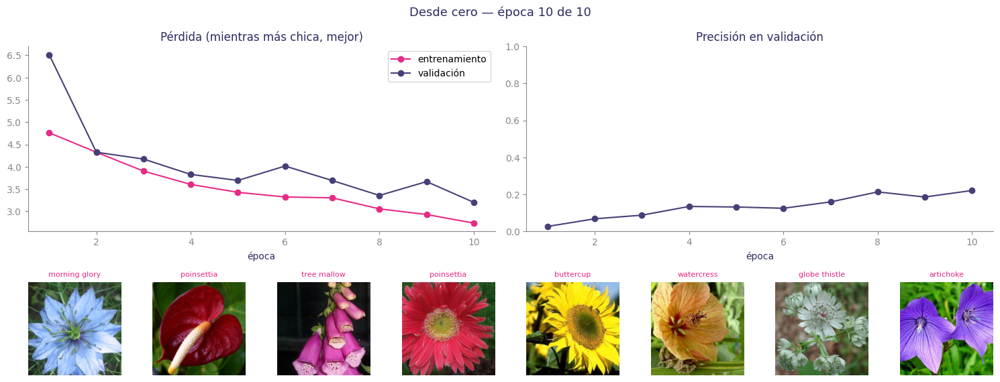

Precisión en validación: 22.2%
Tiempo de entrenamiento: 122 segundos


In [ ]:
EPOCAS = 10
LR = 0.01

torch.manual_seed(0)
modelo_scratch = crear_resnet18(preentrenada=False)
inicio = time.time()
hist_scratch = entrenar(modelo_scratch, train_loader, val_loader, EPOCAS, LR, titulo="Desde cero")
tiempo_scratch = time.time() - inicio
print(f"Tiempo de entrenamiento: {tiempo_scratch:.0f} segundos")

### 2.5 (B) ResNet-18 con fine-tuning

Mismo modelo, mismos datos, mismas épocas, mismo *learning rate*. La **única** diferencia es que parte de los pesos aprendidos en ImageNet.

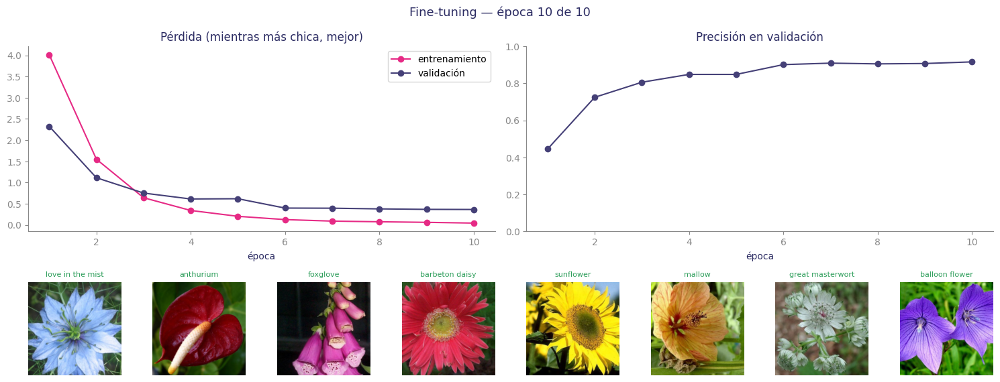

Precisión en validación: 91.6%
Tiempo de entrenamiento: 118 segundos
Pesos guardados en resnet18_flowers.pth


In [ ]:
torch.manual_seed(0)
modelo_ft = crear_resnet18(preentrenada=True)
inicio = time.time()
hist_ft = entrenar(modelo_ft, train_loader, val_loader, EPOCAS, LR, titulo="Fine-tuning")
tiempo_ft = time.time() - inicio
print(f"Tiempo de entrenamiento: {tiempo_ft:.0f} segundos")

torch.save(modelo_ft.state_dict(), "resnet18_flowers.pth")   # la usaremos en la Parte 3
print("Pesos guardados en resnet18_flowers.pth")

### 2.6 Comparación

Ahora sí, la prueba de verdad: el conjunto de **test** (6.149 fotos que ninguno de los dos modelos vio).

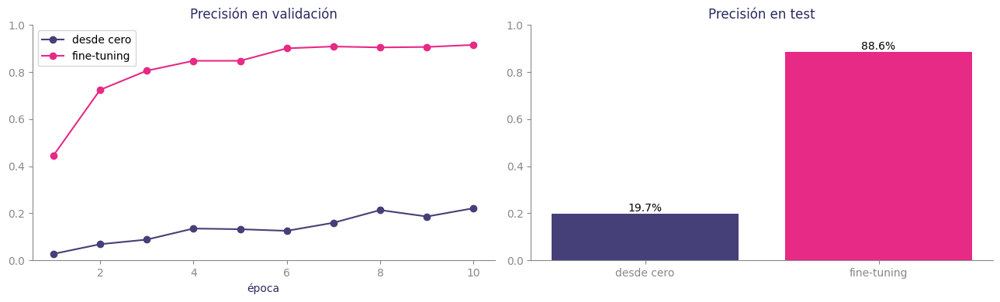

                 test   tiempo
desde cero      19.7%     122s
fine-tuning     88.6%     118s
(Adivinar al azar: 1.0%)


In [ ]:
_, test_scratch = evaluar(modelo_scratch, test_loader)
_, test_ft = evaluar(modelo_ft, test_loader)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epocas = range(1, EPOCAS + 1)
axes[0].plot(epocas, hist_scratch["val_precision"], "o-", color=MORADO, label="desde cero")
axes[0].plot(epocas, hist_ft["val_precision"], "o-", color=ROSA, label="fine-tuning")
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("época")
axes[0].set_title("Precisión en validación")
axes[0].legend()

barras = axes[1].bar(["desde cero", "fine-tuning"], [test_scratch, test_ft], color=[MORADO, ROSA])
axes[1].bar_label(barras, labels=[f"{test_scratch:.1%}", f"{test_ft:.1%}"])
axes[1].set_ylim(0, 1)
axes[1].set_title("Precisión en test")
plt.tight_layout()
plt.show()

print(f"{'':12s} {'test':>8s} {'tiempo':>8s}")
print(f"{'desde cero':12s} {test_scratch:>8.1%} {tiempo_scratch:>7.0f}s")
print(f"{'fine-tuning':12s} {test_ft:>8.1%} {tiempo_ft:>7.0f}s")
print(f"(Adivinar al azar: {1 / 102:.1%})")

Lo esperable es que el modelo **desde cero** apenas aprenda algo: con 10 fotos por clase no le alcanza para descubrir solo qué son los bordes, las texturas y las partes. El modelo con **fine-tuning** debería superar holgadamente el 80%: ya sabía **ver**, y solo tuvo que aprender a **distinguir flores**.

Es la diapositiva "Transfer learning: no partir de cero" funcionando de verdad. Miremos algunas fotos de test con lo que predice cada uno:

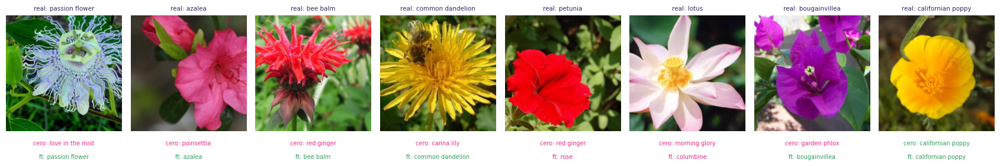

In [ ]:
torch.manual_seed(2)
idx = torch.randperm(len(test_ds))[:8]
x = torch.stack([test_ds[i][0] for i in idx])
y = torch.tensor([test_ds[i][1] for i in idx])
modelo_scratch.eval(); modelo_ft.eval()
with torch.no_grad():
    p_scratch = modelo_scratch(x.to(device)).argmax(dim=1).cpu()
    p_ft = modelo_ft(x.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(1, 8, figsize=(17, 3.4))
for i, ax in enumerate(axes):
    ax.imshow(desnormalizar(x[i]))
    ax.axis("off")
    ax.set_title(f"real: {nombres_clases[y[i]]}", fontsize=7.5, color=AZUL)
    for fila, (nombre, p) in enumerate([("cero", p_scratch[i]), ("ft", p_ft[i])]):
        ax.text(0.5, -0.08 - fila * 0.12, f"{nombre}: {nombres_clases[p]}", transform=ax.transAxes,
                ha="center", va="top", fontsize=7, color="#2E9E5B" if p == y[i] else ROSA)
plt.tight_layout()
plt.show()

## Parte 3: ¿Qué aprendió la ResNet-18?

En la clase vimos que las capas de una CNN aprenden **patrones jerárquicos**: bordes y colores en las primeras capas, texturas después, y partes más adelante. Vimos también la figura de Zeiler & Fergus, donde a cada neurona se le muestra **el patrón que la activa** y **los pedazos de imágenes reales que más la activan**.

Vamos a hacer lo mismo con **nuestra** ResNet-18 fine-tuneada de la Parte 2, en tres pasos:

1. Mirar directamente los **filtros de `conv1`**.
2. **Maximización de activación**: partir de ruido y modificar la imagen para que un canal se encienda lo más posible. Así vemos el patrón que ese canal "busca".
3. Buscar en el dataset los **pedazos de foto que más activan** esos mismos canales.

> Si reiniciaron el entorno de ejecución, ejecuten primero la sección **0. Preparación**. Esta parte usa los pesos guardados en `resnet18_flowers.pth`.

In [ ]:
import os
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
import torchvision.transforms.functional as TF

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Respaldo por si no se corrió la Parte 2 en esta sesión
if "modelo_ft" in globals():
    modelo = modelo_ft
else:
    modelo = resnet18()
    modelo.fc = nn.Linear(512, 102)
    if os.path.exists("resnet18_flowers.pth"):
        modelo.load_state_dict(torch.load("resnet18_flowers.pth", map_location="cpu"))
        print("Cargué los pesos de resnet18_flowers.pth")
    else:
        modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        print("⚠️  No encontré resnet18_flowers.pth: uso la ResNet-18 de ImageNet (sin fine-tuning).")
modelo = modelo.to(device).eval()

if "test_ds" not in globals():
    test_ds = datasets.Flowers102(root="datos", split="test", download=True,
                                  transform=transforms.Compose([
                                      transforms.Resize(256), transforms.CenterCrop(224),
                                      transforms.ToTensor(),
                                      transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]))


def a_imagen(x):
    # Tensor normalizado (3, H, W) -> imagen (H, W, 3) con valores entre 0 y 1
    media = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x.detach().cpu() * std + media).clamp(0, 1).permute(1, 2, 0).numpy()

### 3.1 Los filtros de `conv1`

La primera capa de ResNet-18 tiene **64 filtros** de $7\times7\times3$. Como tienen 3 canales, los podemos dibujar directamente como pequeñas imágenes a color. Compárenlos con los filtros de AlexNet de la diapositiva "Filtros de la capa 1 de AlexNet".

Forma de los filtros de conv1: (64, 3, 7, 7)


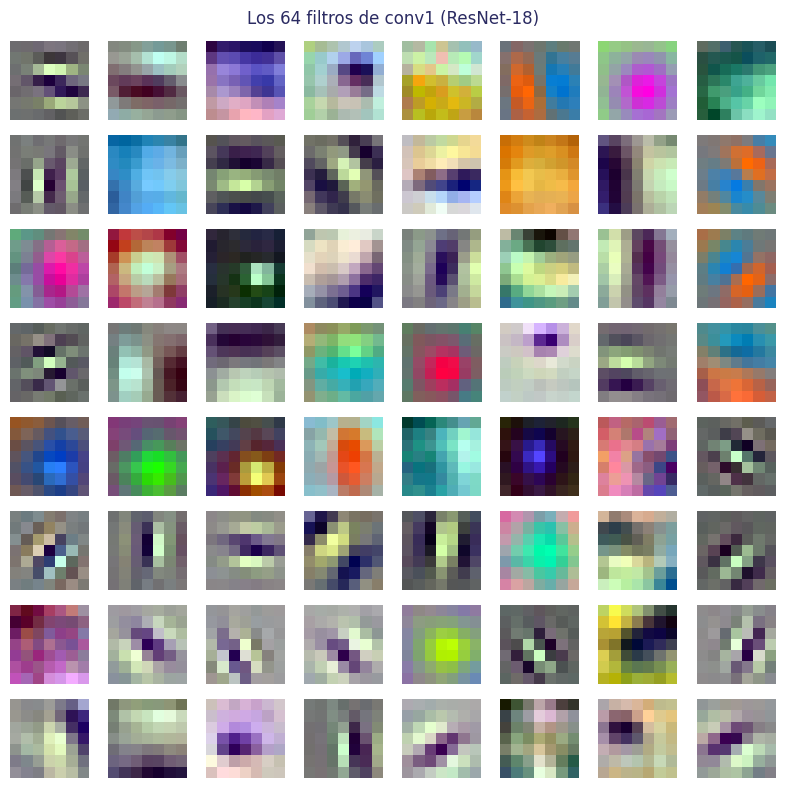

In [ ]:
w = modelo.conv1.weight.detach().cpu()                  # (64, 3, 7, 7)
print("Forma de los filtros de conv1:", tuple(w.shape))

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for i, ax in enumerate(axes.reshape(-1)):
    f = w[i]
    f = (f - f.min()) / (f.max() - f.min())             # cada filtro, entre 0 y 1
    ax.imshow(f.permute(1, 2, 0).numpy(), interpolation="nearest")
    ax.axis("off")
fig.suptitle("Los 64 filtros de conv1 (ResNet-18)", color=AZUL)
plt.tight_layout()
plt.show()

Igual que en AlexNet: **bordes** en distintas orientaciones, **rayas** y **manchas de color**. Nadie los programó: salieron solos al entrenar en ImageNet.

Pero las capas siguientes tienen filtros con 64, 128 o 256 canales: ya no se pueden mirar como imágenes. Para ellas necesitamos otros trucos.

### 3.2 ¿Qué canales vamos a mirar?

Con *hooks* le pedimos a PyTorch que nos guarde las salidas de `layer1`, `layer2` y `layer3` mientras pasamos **1.000 fotos** de test por la red. Para cada canal anotamos su activación máxima en cada foto, y **dónde** ocurrió. Elegimos los 8 canales de cada capa que más se activan en promedio.

In [ ]:
capas = {"layer1": modelo.layer1, "layer2": modelo.layer2, "layer3": modelo.layer3}
STRIDE = {"layer1": 4, "layer2": 8, "layer3": 16}       # cuántos píxeles avanza cada neurona

activaciones = {}


def guardar_salida(nombre):
    def hook(modulo, entrada, salida):
        activaciones[nombre] = salida.detach()
    return hook


ganchos = [capa.register_forward_hook(guardar_salida(n)) for n, capa in capas.items()]
indices = list(range(0, len(test_ds), 6))[:1000]
loader = DataLoader(Subset(test_ds, indices), batch_size=64, num_workers=2)

maximos = {n: [] for n in capas}
posiciones = {n: [] for n in capas}
lados = {}
with torch.no_grad():
    for x, _ in loader:
        modelo(x.to(device))
        for n in capas:
            a = activaciones[n]                         # (B, canales, alto, ancho)
            lados[n] = a.shape[-1]
            valor, pos = a.flatten(2).max(dim=2)        # máximo espacial por canal
            maximos[n].append(valor.cpu())
            posiciones[n].append(pos.cpu())
for g in ganchos:
    g.remove()

maximos = {n: torch.cat(v) for n, v in maximos.items()}       # (1000, canales)
posiciones = {n: torch.cat(v) for n, v in posiciones.items()}
canales = {n: maximos[n].mean(dim=0).topk(8).indices.tolist() for n in capas}

for n in capas:
    print(f"{n}: mapa de {lados[n]} x {lados[n]}, {maximos[n].shape[1]} canales -> elegimos {canales[n]}")

layer1: mapa de 56 x 56, 64 canales -> elegimos [50, 63, 20, 49, 12, 11, 39, 8]
layer2: mapa de 28 x 28, 128 canales -> elegimos [115, 51, 23, 62, 69, 113, 127, 79]
layer3: mapa de 14 x 14, 256 canales -> elegimos [117, 187, 153, 118, 69, 23, 199, 223]


### 3.3 Maximización de activación

Partimos de una imagen de **ruido** y, en vez de cambiar los pesos de la red, cambiamos **la imagen** con descenso de gradiente para que el canal elegido se active lo más posible. Es el mismo ciclo de entrenamiento, ¡pero optimizando la entrada!

Dos trucos para que se vean patrones y no ruido: en cada paso movemos la imagen unos píxeles al azar (*jitter*), y cada tanto la suavizamos un poco (*blur*).

layer1 listo (8 s)
layer2 listo (16 s)
layer3 listo (24 s)


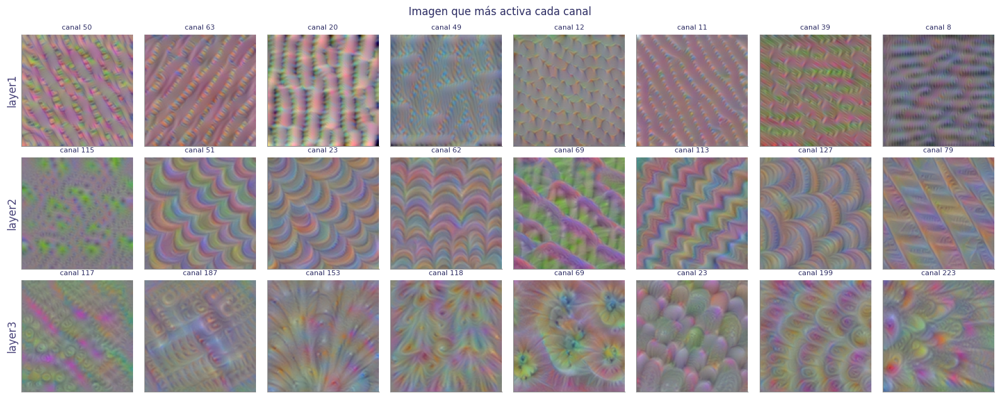

In [ ]:
def maximizar(modelo, capa, canal, pasos=200, tam=128, lr=0.05):
    media = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    minimo, maximo = (0 - media) / std, (1 - media) / std   # límites de una imagen válida

    # partimos de ruido visible (no gris plano): si no, algunos canales no reciben gradiente
    ruido = torch.rand(1, 3, tam, tam, device=device) * 0.4 + 0.3      # valores entre 0.3 y 0.7
    imagen = ((ruido - media) / std).requires_grad_(True)
    optimizer = torch.optim.Adam([imagen], lr=lr)
    salida = {}
    gancho = capa.register_forward_hook(lambda m, i, o: salida.update(a=o))
    for p in modelo.parameters():
        p.requires_grad_(False)                       # la red queda fija
    try:
        for paso in range(pasos):
            dx, dy = np.random.randint(-8, 9, size=2)
            x = torch.roll(imagen, shifts=(int(dx), int(dy)), dims=(2, 3))   # jitter
            optimizer.zero_grad()
            modelo(x)
            perdida = -salida["a"][0, canal].mean()     # queremos MAXIMIZAR la activación
            perdida.backward()
            optimizer.step()
            with torch.no_grad():
                if paso % 4 == 0:
                    imagen.copy_(TF.gaussian_blur(imagen, kernel_size=3, sigma=1.0))  # blur
                imagen.copy_(torch.max(torch.min(imagen, maximo), minimo))
    finally:
        gancho.remove()
        for p in modelo.parameters():
            p.requires_grad_(True)
    return a_imagen(imagen[0])


inicio = time.time()
sinteticas = {}
for n, capa in capas.items():
    sinteticas[n] = []
    for c in canales[n]:
        sinteticas[n].append(maximizar(modelo, capa, c))
    print(f"{n} listo ({time.time() - inicio:.0f} s)")

fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for fila, n in enumerate(capas):
    for col, img in enumerate(sinteticas[n]):
        axes[fila, col].imshow(img)
        axes[fila, col].set_xticks([]); axes[fila, col].set_yticks([])
        axes[fila, col].set_title(f"canal {canales[n][col]}", fontsize=8)
    axes[fila, 0].set_ylabel(n, fontsize=12, color=MORADO)
fig.suptitle("Imagen que más activa cada canal", color=AZUL)
plt.tight_layout()
plt.show()

Fíjense cómo cambian los patrones de una capa a otra. Lo típico es que en `layer1` predominen rayas y colores simples; en `layer2` aparecen **texturas** más elaboradas; en `layer3` los patrones son más **complejos**, a veces con formas que recuerdan pétalos o centros de flores.

### 3.4 Los pedazos de foto que más activan cada canal

Ahora la versión "real": para cada canal buscamos las **6 fotos** donde más se activó y recortamos el pedazo alrededor de **dónde** se activó. El tamaño del recorte crece con la capa, porque las neuronas de capas profundas ven **zonas más grandes** de la imagen (¡el campo receptivo de la clase!).

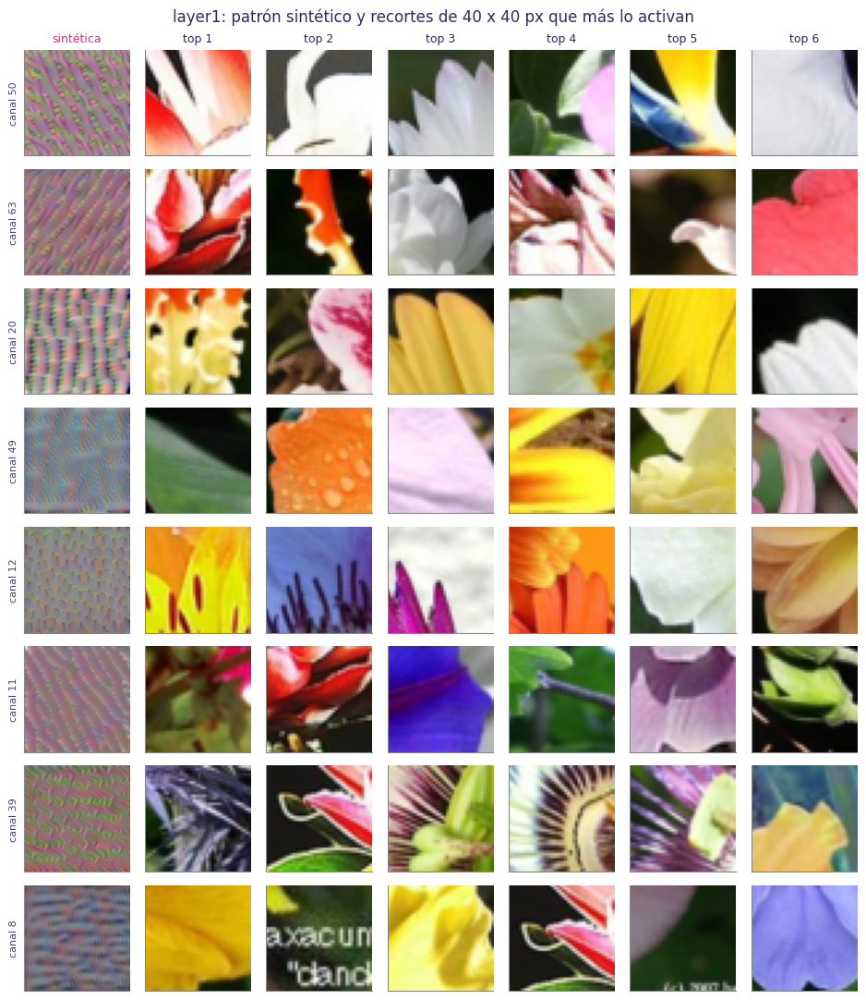

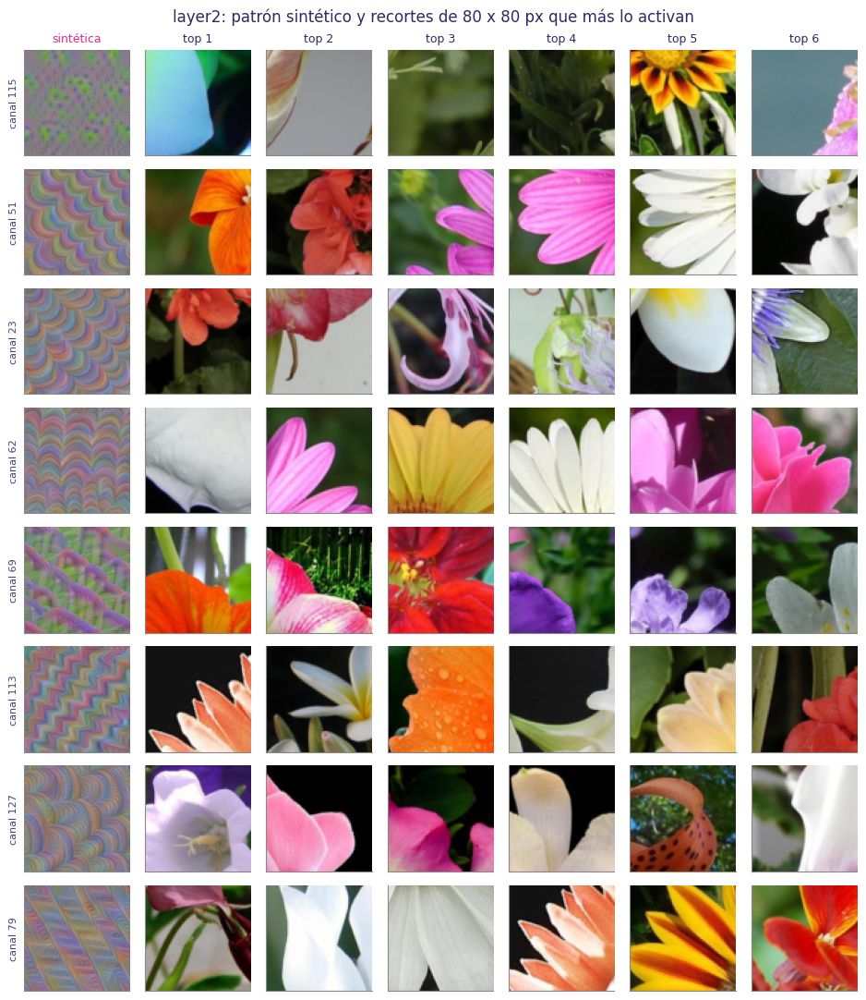

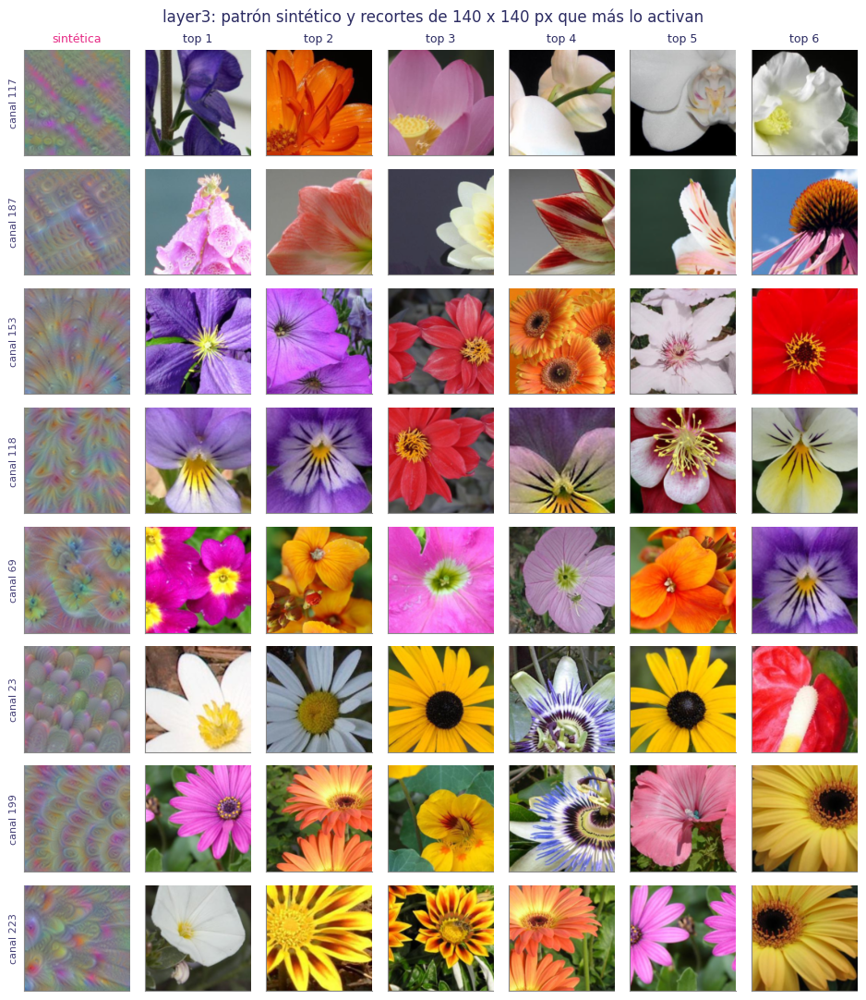

Tiempo de la Parte 3: 31 segundos


In [ ]:
RECORTE = {"layer1": 40, "layer2": 80, "layer3": 140}   # lado del recorte en píxeles


def recortar(img, fila, col, n):
    lado = RECORTE[n]
    cy = int((fila + 0.5) * STRIDE[n])
    cx = int((col + 0.5) * STRIDE[n])
    y0 = min(max(cy - lado // 2, 0), 224 - lado)
    x0 = min(max(cx - lado // 2, 0), 224 - lado)
    return img[y0:y0 + lado, x0:x0 + lado]


for n in capas:
    fig, axes = plt.subplots(8, 7, figsize=(9.5, 11))
    for fila, c in enumerate(canales[n]):
        axes[fila, 0].imshow(sinteticas[n][fila])
        mejores = maximos[n][:, c].topk(6).indices
        for col, k in enumerate(mejores.tolist(), start=1):
            img = a_imagen(test_ds[indices[k]][0])
            f, cc = divmod(posiciones[n][k, c].item(), lados[n])
            axes[fila, col].imshow(recortar(img, f, cc, n))
        for ax in axes[fila]:
            ax.set_xticks([]); ax.set_yticks([])
        axes[fila, 0].set_ylabel(f"canal {c}", fontsize=8, color=MORADO)
    axes[0, 0].set_title("sintética", fontsize=9, color=ROSA)
    for col in range(1, 7):
        axes[0, col].set_title(f"top {col}", fontsize=9)
    fig.suptitle(f"{n}: patrón sintético y recortes de {RECORTE[n]} x {RECORTE[n]} px que más lo activan",
                 color=AZUL)
    plt.tight_layout()
    plt.show()

print(f"Tiempo de la Parte 3: {time.time() - inicio:.0f} segundos")

Comparen con la figura de **Zeiler & Fergus** de la clase: cada fila agrupa recortes que se parecen entre sí, y se parecen al patrón sintético de la izquierda. Y a medida que avanzamos de `layer1` a `layer3`, los recortes son **más grandes** y los patrones **más complejos**: es la jerarquía bordes → texturas → partes, ¡ahora en nuestra propia red!

## Resumen

* Una convolución es un **detector de patrones locales**: en PyTorch es `F.conv2d` o `nn.Conv2d`, y sus filtros se **aprenden**.
* En AlexNet casi todos los parámetros están en las **capas lineales**: los filtros convolucionales son baratos porque se reutilizan en toda la imagen.
* Con solo 10 fotos por clase, una ResNet-18 **desde cero** casi no aprende, mientras que con **fine-tuning** reconoce la gran mayoría de las flores: transfer learning en acción.
* Las capas de una CNN aprenden una **jerarquía** de patrones, y la podemos ver con maximización de activación y con los recortes que más activan cada canal.

In [ ]:
if "INICIO_LAB" in globals():
    print(f"Tiempo total del laboratorio: {(time.time() - INICIO_LAB) / 60:.1f} minutos")

Tiempo total del laboratorio: 6.7 minutos
